# Fraction of total CR energy above an energy threshold

For the steady-state proton and electron spectra, calculate the fraction of the total energy (integral over the full spectrum) that is carried by particles above a given energy threshold:

$$ F(E_\mathrm{th}) = \frac{\int_{p(E_\mathrm{th})}^{p_\mathrm{max}} 4\pi p^2 \, E_\mathrm{kin}(p) \, f(p) \, dp}{\int_{p_\mathrm{min}}^{p_\mathrm{max}} 4\pi p^2 \, E_\mathrm{kin}(p) \, f(p) \, dp} $$

i.e. a complementary cumulative energy fraction, decreasing monotonically from 1 (at the lowest energy of the grid) to 0 (at $p_\mathrm{max}$).

Rather than reading `pmax_prot`/`pmax_electr` from `bowshock_config.json` (which correspond to the termination-shock values), we explicitly provide the maximum momenta for **both** the outer and termination shock, taken from the manuscript table (intersection of acceleration and loss timescales). Outer-shock curves are plotted as dashed lines, termination-shock curves as solid lines, following the reference calculation in `plot_steady_state_spectrum.ipynb`.

In [1]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

import json

from synch_emission_functions import f_p_0, f_e_0, ekin, mp, me, c, ep_ratio

## Load bowshock config (for colors/labels) and set up momentum grids

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config, only used here for plot colors/labels
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [3]:
pp_arr = np.logspace(0.83, 5, 200)
print(
    f"Minimum & maximum of normalised momentum (protons): {(pp_arr.min() * mp * c**2).to(u.GeV):.5e}, {(pp_arr.max() * mp * c**2).to(u.GeV):.5e}"
)

pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5f}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)

Kep, pp0, pe0 = (
    ep_ratio()
)  # get the normalisation for the electron spectrum based on the proton spectrum at 10 GeV, and the corresponding momenta

Minimum & maximum of normalised momentum (protons): 6.34350e+00 GeV, 9.38272e+04 GeV
Minimum & maximum of normalised momentum (electrons): 0.05110 GeV, 5.10999e+03 GeV
ep ratio parameters: 0.01, 10.658, 19569.512


In [4]:
alpha_inj_p = 4.2
alpha_inj_e = 4.2

dens_val = 1e-25 * (u.g / u.cm**3)
mag_val = 1 * u.uG
vel_val = 100 * u.km / u.s
r_pos = 5 * u.pc

## Maximum momenta for outer & termination shock

Taken directly from the manuscript table (values of $p_\mathrm{max}$ in units of $m_p c$ / $m_e c$, determined from the intersection of the acceleration and energy-loss timescales), rather than from `bowshock_config.json`'s `pmax_prot` / `pmax_electr` (which hold only the termination-shock values).

In [5]:
# p_max in units of m_p c / m_e c, from the acceleration/loss-timescale intersection (manuscript table)
pmax_table = {
    "ISM-v40-MDiff": {
        "outer": {"pmax_prot": 1.88e3, "pmax_electr": 1.41e5},
        "term":  {"pmax_prot": 4.58e4, "pmax_electr": 1.55e6},
    },
    "ISM-v40-LDiff": {
        "outer": {"pmax_prot": 1.20e5, "pmax_electr": 7.19e4},
        "term":  {"pmax_prot": 4.60e6, "pmax_electr": 1.75e7},
    },
    "ISM-v40-HDiff": {
        "outer": {"pmax_prot": 19.5,   "pmax_electr": 2.20e4},
        "term":  {"pmax_prot": 4.56e2, "pmax_electr": 2.21e5},
    },
    "ISM-v100-MDiff": {
        "outer": {"pmax_prot": 1.83e3, "pmax_electr": 1.41e5},
        "term":  {"pmax_prot": 9.53e3, "pmax_electr": 4.50e5},
    },
}

sim_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]
shock_linestyles = {"outer": "--", "term": "-"}
shock_labels = {"outer": "Outer", "term": "Term."}

## Fraction of total energy above threshold

Helper that, given the steady-state spectrum $f(p)$ on grid `p_arr`, returns the energy-weighted spectrum integrand and the cumulative-from-above energy fraction $F(E_\mathrm{th})$.

In [6]:
def energy_fraction_above_threshold(p_arr, f0, mass):
    """Fraction of total energy contained above each energy threshold in p_arr.

    p_arr : normalised momentum grid (sorted ascending)
    f0    : steady-state spectrum evaluated on p_arr
    mass  : particle mass (mp or me), used to convert normalised kinetic energy to physical units

    Returns (E_arr, frac) where E_arr is the kinetic energy grid (GeV) and frac(E) = fraction of the
    total energy integral coming from particles with energy >= E.
    """
    dE_dp_integrand = 4 * np.pi * p_arr**2 * ekin(p_arr) * f0

    total_energy = np.trapz(dE_dp_integrand, x=p_arr)

    # cumulative integral from p_arr[0] up to each grid point
    cumulative_from_below = np.concatenate((
        [0.0],
        np.cumsum(0.5 * (dE_dp_integrand[1:] + dE_dp_integrand[:-1]) * np.diff(p_arr))
    ))

    frac_above = 1 - cumulative_from_below / total_energy

    E_arr = (ekin(p_arr) * mass * c**2).to(u.GeV)

    return E_arr, frac_above

## Protons: fraction of total energy vs. energy threshold

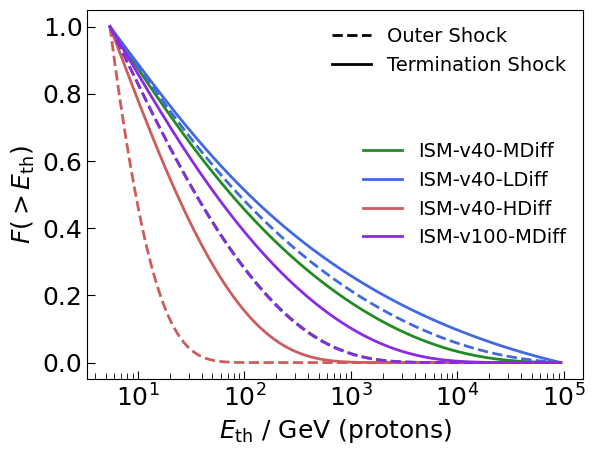

In [18]:
fig, ax = plt.subplots()

for sim_name in sim_names:
    for shock in ["outer", "term"]:
        pmax_p = pmax_table[sim_name][shock]["pmax_prot"]

        fp0 = f_p_0(
            alpha_inj_p,
            pp_arr,
            dens_val,
            vel_val,
            pmax=pmax_p,
            vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
        )

        Ep_arr, frac_p = energy_fraction_above_threshold(pp_arr, fp0, mp)

        label = bowshock_config[sim_name]["label"] if shock == "term" else None
        ax.semilogx(
            Ep_arr.value,
            frac_p,
            ls=shock_linestyles[shock],
            color=bowshock_config[sim_name]["color"],
            lw=2.0,
            label=label,
        )

ax.set_xlabel(r"$E_\mathrm{th}$ / GeV (protons)", fontsize=18)
ax.set_ylabel(r"$F(>E_\mathrm{th})$", fontsize=18)

# ax.set_ylim(1e-4, 1)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

sim_legend = ax.legend(loc="center right", prop={"size": 14}, frameon=False)
ax.add_artist(sim_legend)

shock_handles = [
    mlines.Line2D([], [], color="black", ls="--", lw=2.0, label="Outer Shock"),
    mlines.Line2D([], [], color="black", ls="-", lw=2.0, label="Termination Shock"),
]
ax.legend(handles=shock_handles, loc="upper right", prop={"size": 14}, frameon=False)

# ax.axhline(y=0.1, color="k", ls="-", lw=3, label=r"$F(>E_\mathrm{th}) = 0.1$")

fig.savefig(f"{fig_dir}/energy_fraction_threshold_proton.pdf", dpi=150, bbox_inches='tight')

## Electrons: fraction of total energy vs. energy threshold

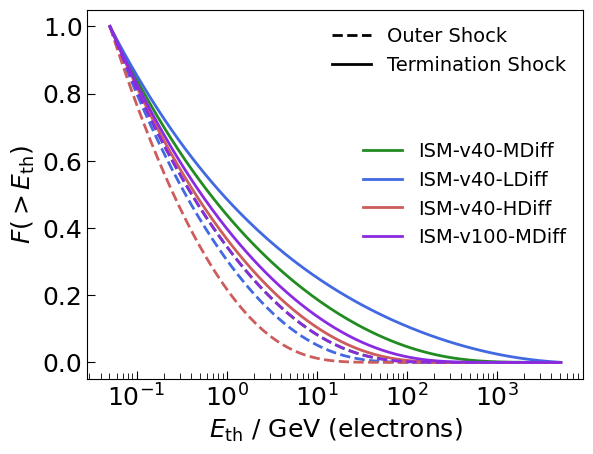

In [10]:
fig, ax = plt.subplots()

for sim_name in sim_names:
    for shock in ["outer", "term"]:
        pmax_p = pmax_table[sim_name][shock]["pmax_prot"]
        pmax_e = pmax_table[sim_name][shock]["pmax_electr"]

        fe0 = f_e_0(
            alpha_inj_e,
            pe_arr,
            dens_val,
            mag_val,
            Tstar=1e4 * u.K,  # assumed based on stellar track from Ekstrom+2012
            vel=vel_val,
            pmax=pmax_e,
            vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
            r_pos=r_pos,
        )

        # renormalise electron spectrum based on the e/p ratio at 10 GeV, as in the reference notebook
        fe = (
            Kep
            * f_p_0(
                alpha_inj_p,
                pp0,
                dens_val,
                vel_val,
                pmax=pmax_p,
                vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
            )
            / f_e_0(
                alpha_inj_e,
                pe0,
                dens_val,
                mag_val,
                Tstar=1e4 * u.K,
                vel=vel_val,
                pmax=pmax_e,
                vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
                r_pos=r_pos,
            )
            * fe0
        )

        Ee_arr, frac_e = energy_fraction_above_threshold(pe_arr, fe, me)

        label = bowshock_config[sim_name]["label"] if shock == "term" else None
        ax.semilogx(
            Ee_arr.value,
            frac_e,
            ls=shock_linestyles[shock],
            color=bowshock_config[sim_name]["color"],
            lw=2.0,
            label=label,
        )

ax.set_xlabel(r"$E_\mathrm{th}$ / GeV (electrons)", fontsize=18)
ax.set_ylabel(r"$F(>E_\mathrm{th})$", fontsize=18)

# ax.set_ylim(1e-4, 2)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

sim_legend = ax.legend(loc="center right", prop={"size": 14}, frameon=False)
ax.add_artist(sim_legend)

shock_handles = [
    mlines.Line2D([], [], color="black", ls="--", lw=2.0, label="Outer Shock"),
    mlines.Line2D([], [], color="black", ls="-", lw=2.0, label="Termination Shock"),
]
ax.legend(handles=shock_handles, loc="upper right", prop={"size": 14}, frameon=False)

fig.savefig(f"{fig_dir}/energy_fraction_threshold_electron.pdf", dpi=150, bbox_inches='tight')